# ANN for the SABR approximation: McGhee (2018) §5.1

Train the 14 → N (softplus) → 10 network on the Hagan β=1 dataset (T ∈ [1D, 1Y]) for N ∈ {250, 500, 750, 1000}, then check it against the error ranges the paper reports for Figures 2–6.

Training recipe (the paper's network, loss and optimizer; where the paper is silent we chose):
- one softplus hidden layer, softplus output, MSE on implied vol, Adam, batch 32 (Keras default)
- inputs min-max scaled to [0, 1] on the training set (stored in the model)
- learning rate 1e-3, halved after 100 epochs without a new best loss; stop after 500 epochs without one (≈ 11–15k epochs)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import norm

from src.hagan import DATA_DIR, COLUMNS_X, COLUMNS_Y, hagan_iv, make_strikes, check_against_paper
from src.model import SABRNet, train, smile

plt.rcParams["figure.dpi"] = 110
torch.manual_seed(0)

## 1. Data
The Hagan dataset: 100k grid points and 150k random points for training, plus 50k random points for testing.

In [2]:
d = np.load(DATA_DIR / "hagan_1d_1y.npz")
X_train, y_train, X_test, y_test = d["X_train"], d["y_train"], d["X_test"], d["y_test"]
print({k: d[k].shape for k in ["X_train", "y_train", "X_test", "y_test"]})
pd.DataFrame(np.hstack((X_train, y_train)), columns=COLUMNS_X + COLUMNS_Y).describe().T.round(4)

{'X_train': (250000, 14), 'y_train': (250000, 10), 'X_test': (50000, 14), 'y_test': (50000, 10)}


,count,mean,std,min,25%,50%,75%,max
T,250000.0,0.5015,0.2890,0.0027,0.2519,0.5020,0.7505,1.0000
alpha,250000.0,0.2750,0.1355,0.0500,0.1500,0.2750,0.4000,0.5000
nu,250000.0,1.1342,1.3835,0.0144,0.4282,0.8744,1.3518,22.0605
rho,250000.0,-0.0006,0.5420,-0.9000,-0.5000,-0.0008,0.5000,0.9000
K1,250000.0,0.5281,0.2304,0.0291,0.3402,0.5270,0.7203,0.9946
K2,250000.0,0.5978,0.2177,0.0511,0.4294,0.6124,0.7807,0.9966
K3,250000.0,0.6823,0.2004,0.0898,0.5389,0.7145,0.8502,0.9987
K4,250000.0,0.7856,0.1822,0.1576,0.6683,0.8300,0.9349,1.0482
K5,250000.0,0.9134,0.1789,0.2768,0.8104,0.9415,1.0237,1.5400
K6,250000.0,1.0732,0.2251,0.4780,0.9461,1.0299,1.1640,2.3512


Sanity check of the labels: Hagan against paper Table 6. The paper rounds to 0.01%, so a max error of ±0.5 bp is the noise floor.

In [3]:
print(f"Max error vs. Table 6: {check_against_paper():.2f} bp")

Max error vs. Table 6: 0.53 bp


## 2. Training
The first cell trains all sizes in parallel (`src/train_ann.py`, one process per size) and redraws the loss every 10 s. Interrupting the cell stops training. `data/ann_{N}.pt` is a checkpoint saved every 10 epochs: rerunning continues from it up to `EPOCHS` (sizes already there, or auto-stopped, are skipped). Delete the file to retrain from scratch. Full training takes 1–2 days of CPU time per size.


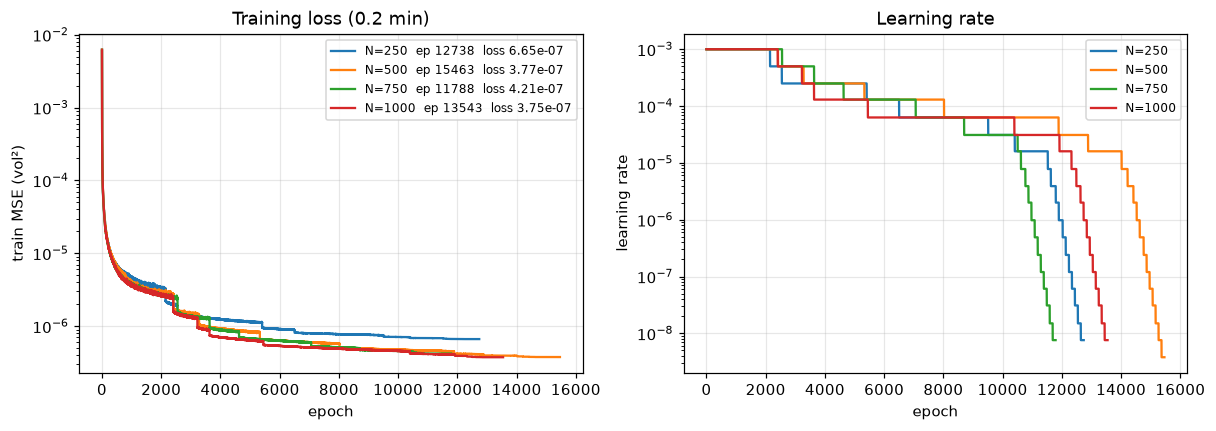

exit code 0


In [4]:
import os, re, signal, subprocess, sys, time
from IPython.display import clear_output

SIZES = [250, 500, 750, 1000]
EPOCHS = 20000  # cap, counting epochs already in data/ann_{N}.pt; runs normally auto-stop before it

def read_log(h):
    rows = re.findall(r"epoch\s+(\d+)/\d+\s+loss (\S+)\s+lr (\S+)", (DATA_DIR / f"ann_{h}.log").read_text()) \
        if (DATA_DIR / f"ann_{h}.log").exists() else []
    return np.array(rows, dtype=float).reshape(-1, 3)

def plot_progress(elapsed):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    for h in SIZES:
        r = read_log(h)
        if len(r):
            a1.semilogy(r[:, 0], r[:, 1], label=f"N={h}  ep {int(r[-1, 0])}  loss {r[-1, 1]:.2e}")
            a2.semilogy(r[:, 0], r[:, 2], label=f"N={h}")
    a1.set(xlabel="epoch", ylabel="train MSE (vol²)", title=f"Training loss ({elapsed / 60:.1f} min)")
    a2.set(xlabel="epoch", ylabel="learning rate", title="Learning rate")
    for a in (a1, a2):
        a.grid(alpha=0.3)
        if a.lines: a.legend(fontsize=8)
    plt.show()

proc = subprocess.Popen([sys.executable, "-m", "src.train_ann", *map(str, SIZES), "--epochs", str(EPOCHS)],
                        start_new_session=True)  # own process group, so an interrupt can stop all workers
t0 = time.time()
try:
    while proc.poll() is None:
        clear_output(wait=True); plot_progress(time.time() - t0)
        time.sleep(10)
except KeyboardInterrupt:
    os.killpg(proc.pid, signal.SIGTERM)
    print("training stopped")
clear_output(wait=True); plot_progress(time.time() - t0)
print("exit code", proc.wait())

--- N=250 ---
12738 epochs, final train MSE 6.653e-07
--- N=500 ---
15463 epochs, final train MSE 3.772e-07
--- N=750 ---
11788 epochs, final train MSE 4.213e-07
--- N=1000 ---
13543 epochs, final train MSE 3.750e-07


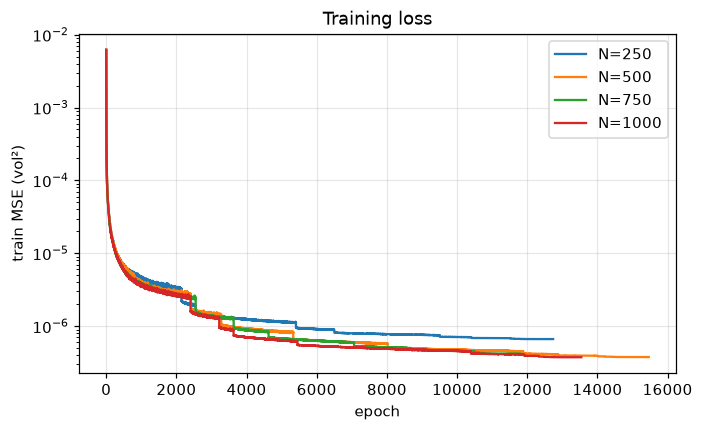

In [5]:
nets, losses = {}, {}
for h in SIZES:
    path = DATA_DIR / f"ann_{h}.pt"
    net = SABRNet(h)
    print(f"--- N={h} ---")
    if path.exists():
        ckpt = torch.load(path)
        net.load_state_dict(ckpt["state"])
        losses[h] = ckpt["losses"]
    else:  # same recipe as the cell above, in-process
        net.set_input_range(X_train)
        losses[h] = train(net, X_train, y_train, epochs=EPOCHS, log_every=1)
        torch.save({"state": net.state_dict(), "losses": losses[h]}, path)
    print(f"{len(losses[h])} epochs, final train MSE {losses[h][-1]:.3e}")
    nets[h] = net.eval()

fig, ax = plt.subplots(figsize=(7, 4))
for h in SIZES:
    ax.semilogy(losses[h], label=f"N={h}")
ax.set(xlabel="epoch", ylabel="train MSE (vol²)", title="Training loss")
ax.legend(); ax.grid(alpha=0.3)


## 3. Out-of-sample error on the 50k test set
Errors are in implied-vol basis points (1 bp = 0.01%). The paper reports no aggregate test metric, so these numbers are our own baseline.

In [6]:
err = {h: (nets[h].predict(X_test) - y_test) * 1e4 for h in SIZES}
pd.DataFrame({h: {"MAE (bp)": np.abs(e).mean(), "RMSE (bp)": np.sqrt((e**2).mean()),
                  "p99 |err| (bp)": np.percentile(np.abs(e), 99), "max |err| (bp)": np.abs(e).max()}
              for h, e in err.items()}).T.round(3)

,MAE (bp),RMSE (bp),p99 |err| (bp),max |err| (bp)
250,4.718,7.039,25.063,153.195
500,3.599,5.392,18.991,133.111
750,3.777,5.632,20.073,130.306
1000,3.550,5.265,18.479,131.003


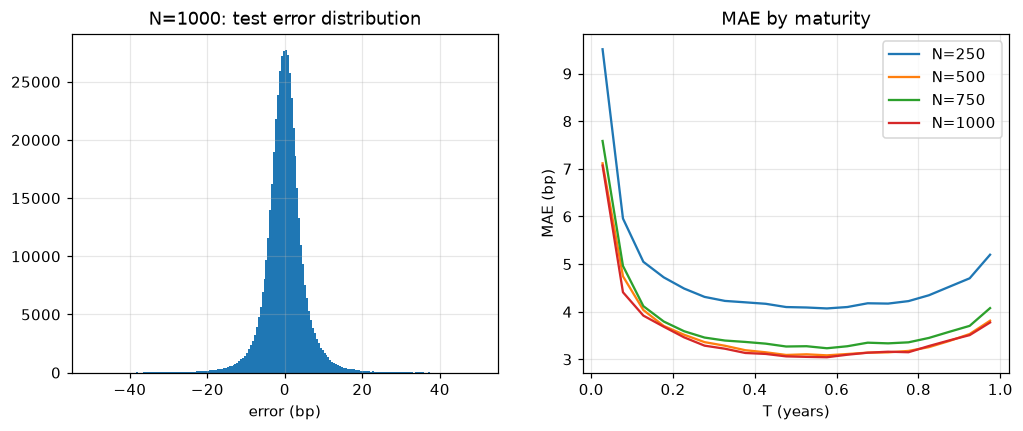

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(err[max(SIZES)].ravel(), bins=200, range=(-50, 50))
axes[0].set(xlabel="error (bp)", title=f"N={max(SIZES)}: test error distribution")
T_test = X_test[:, 0]
bins = np.linspace(T_test.min(), T_test.max(), 21)
idx = np.digitize(T_test, bins)
for h in SIZES:
    mae_T = [np.abs(err[h][idx == i]).mean() for i in range(1, len(bins))]
    axes[1].plot((bins[:-1] + bins[1:]) / 2, mae_T, label=f"N={h}")
axes[1].set(xlabel="T (years)", ylabel="MAE (bp)", title="MAE by maturity"); axes[1].legend()
for a in axes: a.grid(alpha=0.3)

## 4. Paper Figures 2–4: smiles from all four networks
Both the Hagan reference and the ANN outputs are taken at the 10 strikes and passed through a cubic spline (§4.3), so the error below is the network error alone, evaluated on a fine strike grid. Units: vol %.

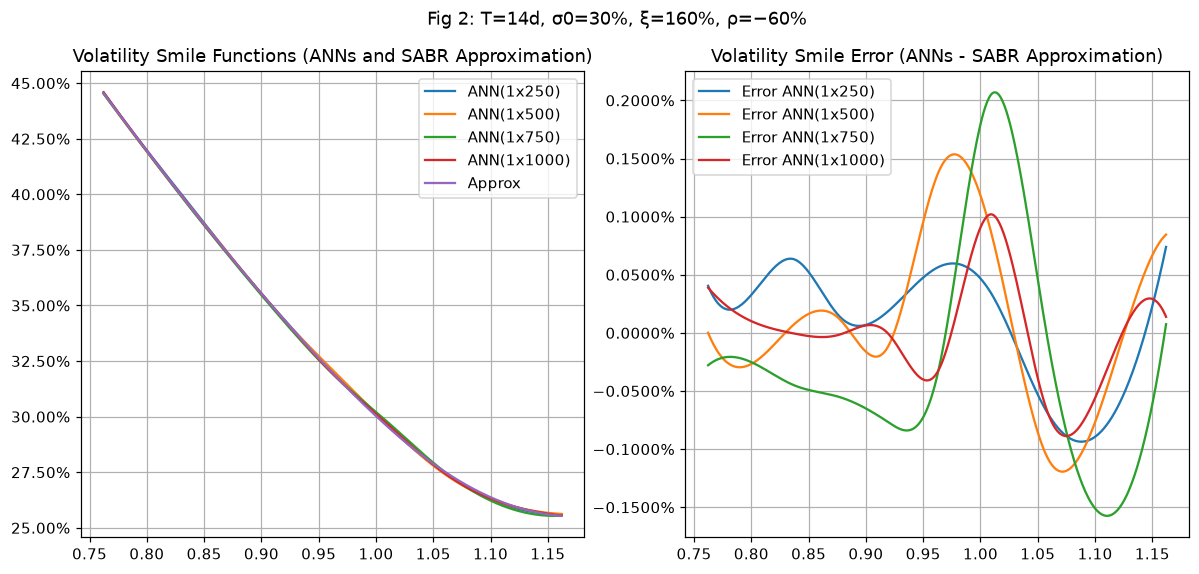

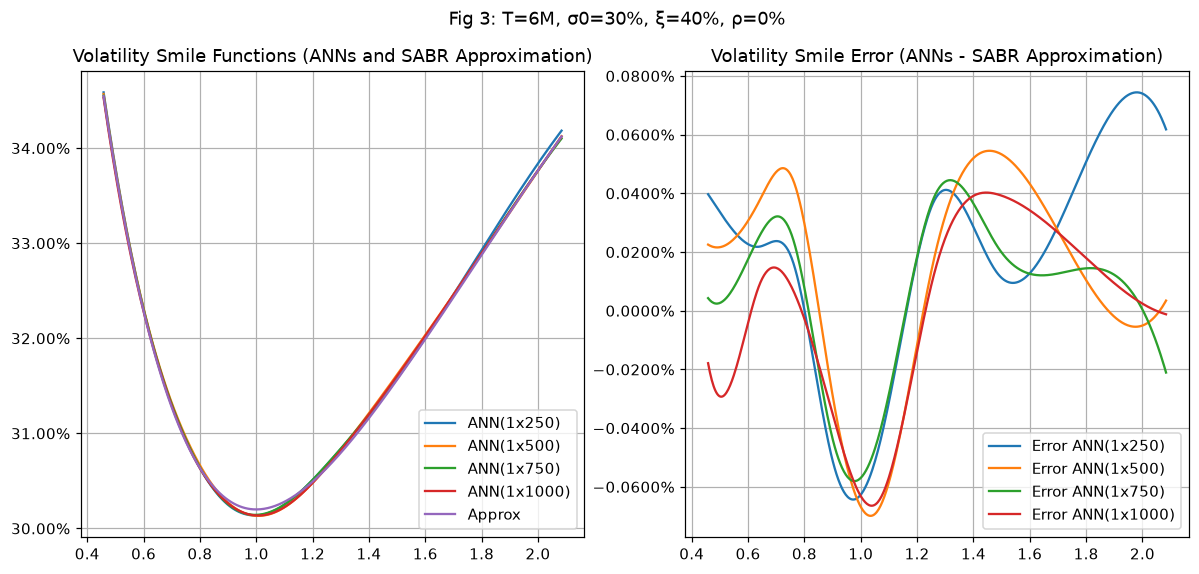

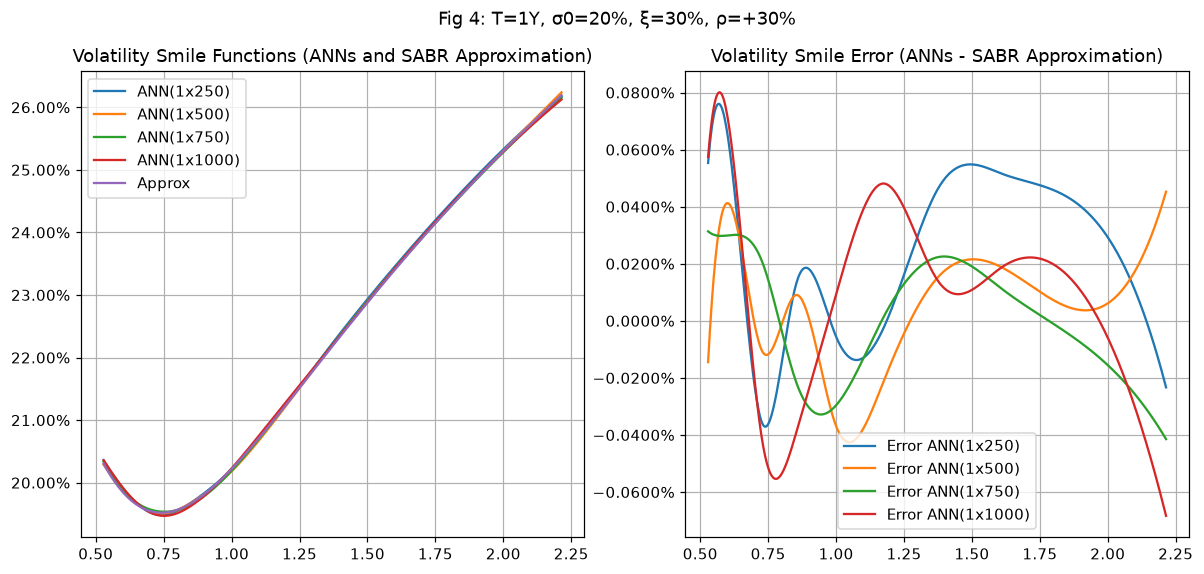

,figure,N,ours min (%),ours max (%),paper min (%),paper max (%),within paper range
0,Fig 2,250,-0.0936,0.0739,-0.030,0.10,False
1,Fig 2,500,-0.1194,0.1536,-0.030,0.10,False
2,Fig 2,750,-0.1574,0.2069,-0.030,0.10,False
3,Fig 2,1000,-0.0888,0.1020,-0.030,0.10,False
4,Fig 3,250,-0.0643,0.0744,-0.015,0.02,False
5,Fig 3,500,-0.0699,0.0545,-0.015,0.02,False
6,Fig 3,750,-0.0580,0.0445,-0.015,0.02,False
7,Fig 3,1000,-0.0664,0.0403,-0.015,0.02,False
8,Fig 4,250,-0.0371,0.0760,-0.025,0.02,False
9,Fig 4,500,-0.0426,0.0453,-0.025,0.02,False


In [8]:
from matplotlib.ticker import PercentFormatter

def smiles(T, a, nu, rho, h, n=500):
    K = make_strikes(1.0, T, a, rho, nu)
    Kf = np.linspace(K[0], K[-1], n)
    ref = smile(K, hagan_iv(1.0, K, T, a, 1.0, rho, nu))(Kf)
    ann = smile(K, nets[h].predict(np.r_[T, a, nu, rho, K][None])[0])(Kf)
    return Kf, ref, ann

def paper_plot(K, ref, curves, what, decimals=(2, 4), suptitle=""):
    """Paper layout: functions on the left, ANN − Approx error on the right, y-axes in %."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5))
    for name, c in curves.items():
        left.plot(K, c, label=name)
        right.plot(K, c - ref, label=f"Error {name}")
    left.plot(K, ref, label="Approx")
    left.set_title(f"{what} Functions (ANNs and SABR Approximation)")
    right.set_title(f"{what} Error (ANNs - SABR Approximation)")
    for ax, dec in zip((left, right), decimals):
        ax.yaxis.set_major_formatter(PercentFormatter(1, dec))
        ax.grid(); ax.legend()
    fig.suptitle(suptitle)
    plt.show()

FIGS = {  # name: (T, sigma0, xi, rho), paper error range in vol %
    "Fig 2: T=14d, σ0=30%, ξ=160%, ρ=−60%": ((14 / 365, 0.30, 1.60, -0.60), (-0.03, 0.10)),
    "Fig 3: T=6M, σ0=30%, ξ=40%, ρ=0%":     ((0.5, 0.30, 0.40, 0.00), (-0.015, 0.02)),
    "Fig 4: T=1Y, σ0=20%, ξ=30%, ρ=+30%":   ((1.0, 0.20, 0.30, 0.30), (-0.025, 0.02)),
}
rows = []
for name, (p, paper) in FIGS.items():
    curves = {}
    for h in SIZES:
        Kf, ref, ann = smiles(*p, h)
        curves[f"ANN(1x{h})"] = ann
        e = (ann - ref) * 100
        rows.append({"figure": name[:5], "N": h, "ours min (%)": e.min(), "ours max (%)": e.max(),
                     "paper min (%)": paper[0], "paper max (%)": paper[1],
                     "within paper range": paper[0] <= e.min() and e.max() <= paper[1]})
    paper_plot(Kf, ref, curves, "Volatility Smile", suptitle=name)
pd.DataFrame(rows).round(4)

## 5. Paper Figures 5–6: smile, CDF and PDF (largest trained N)
Black prices with F=1 and no discounting: CDF(K) = 1 + ∂C/∂K and PDF(K) = ∂²C/∂K², both by finite differences on the spline smile. Units are % (probability × 100, density × 100), as in the paper.

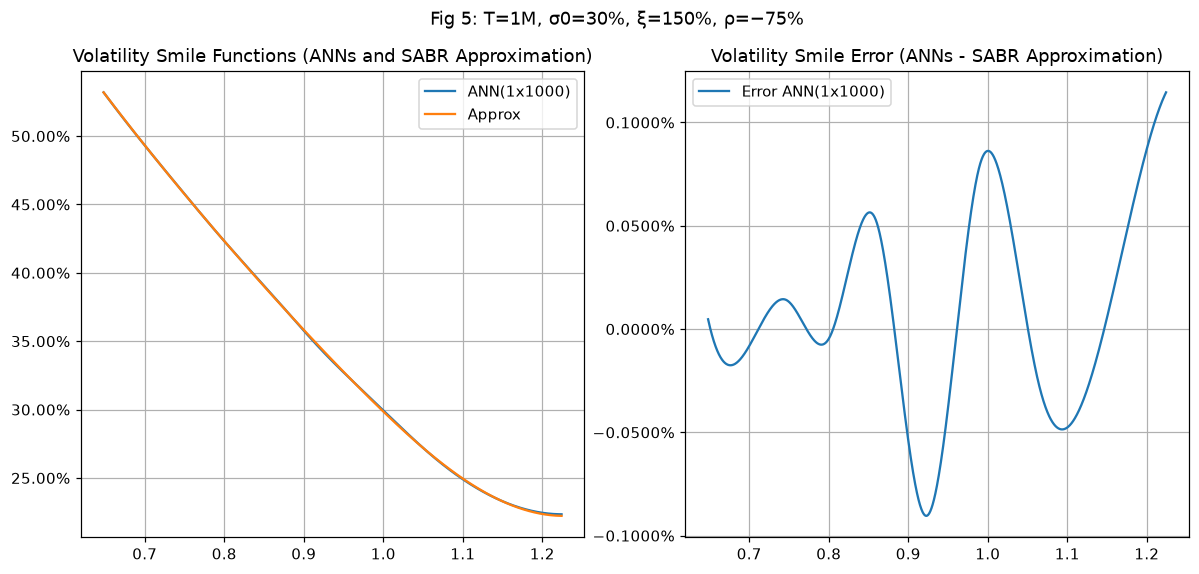

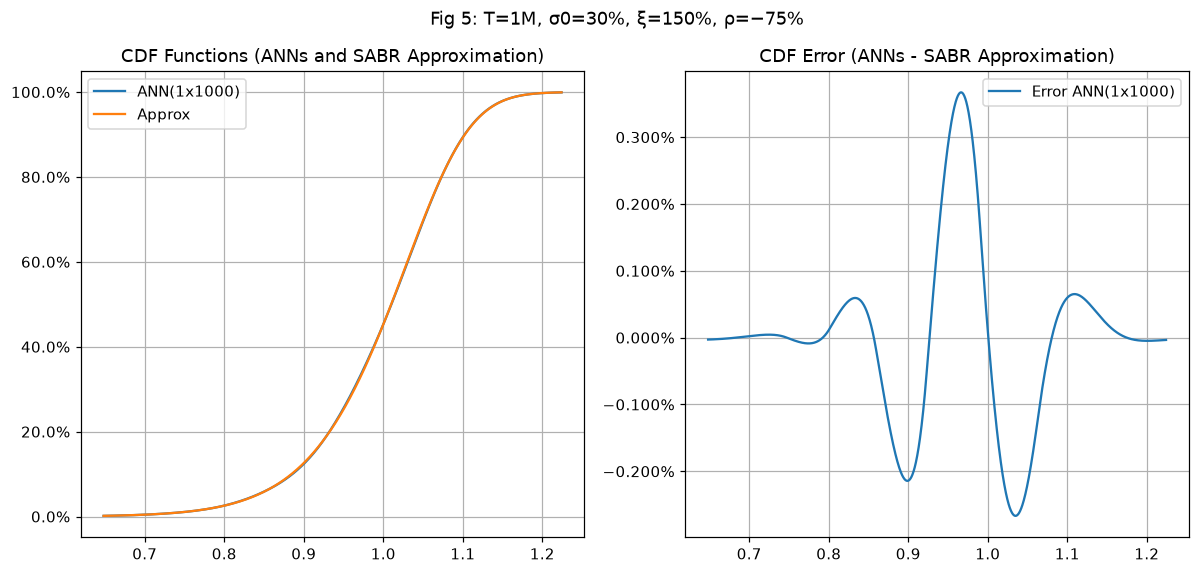

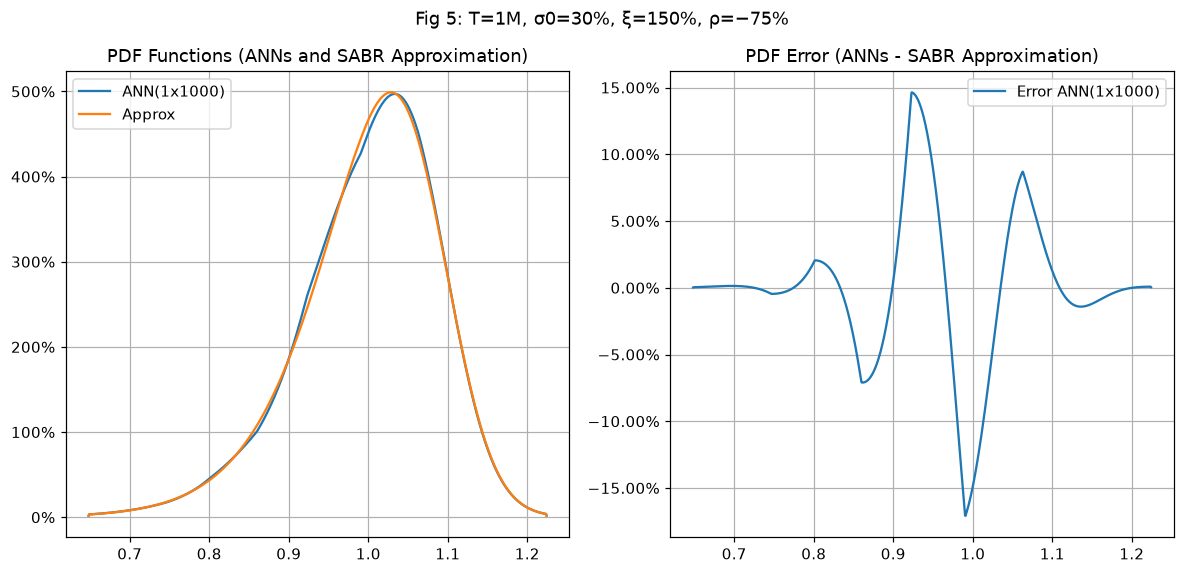

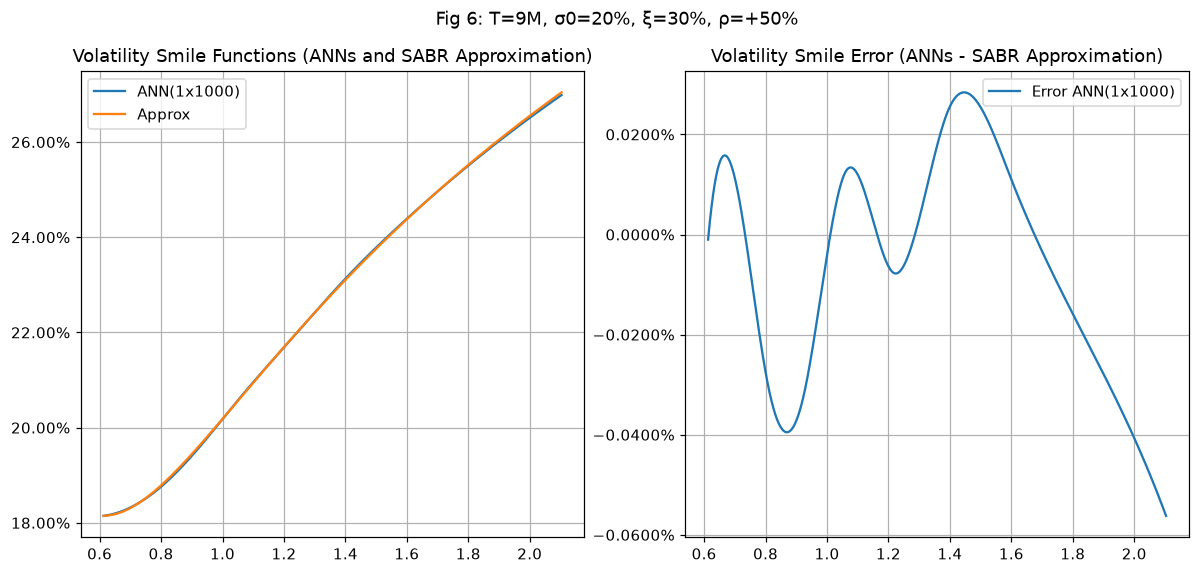

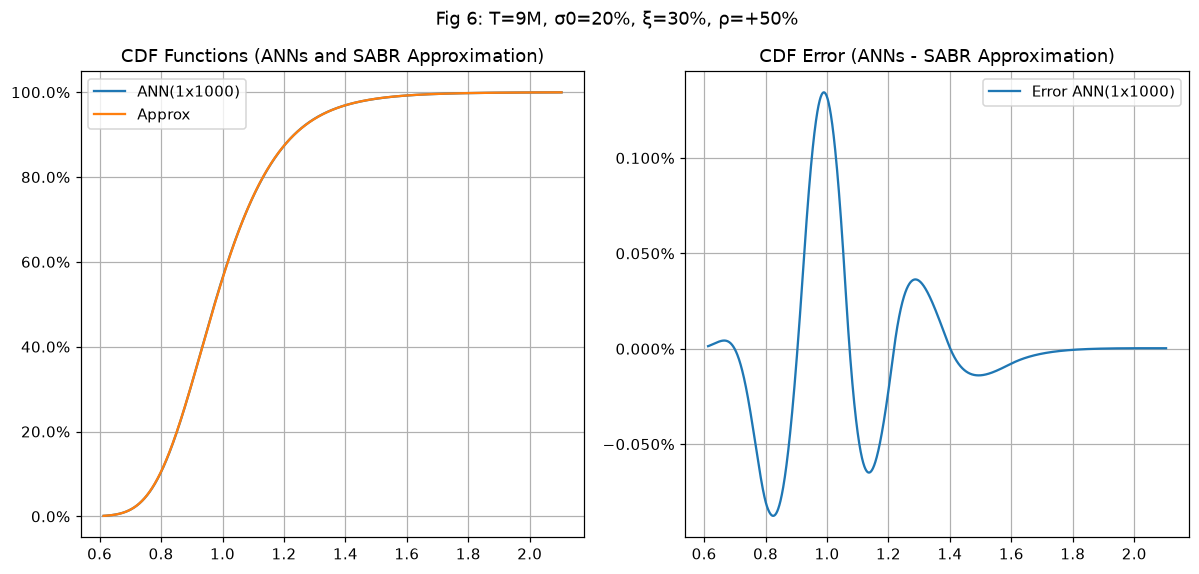

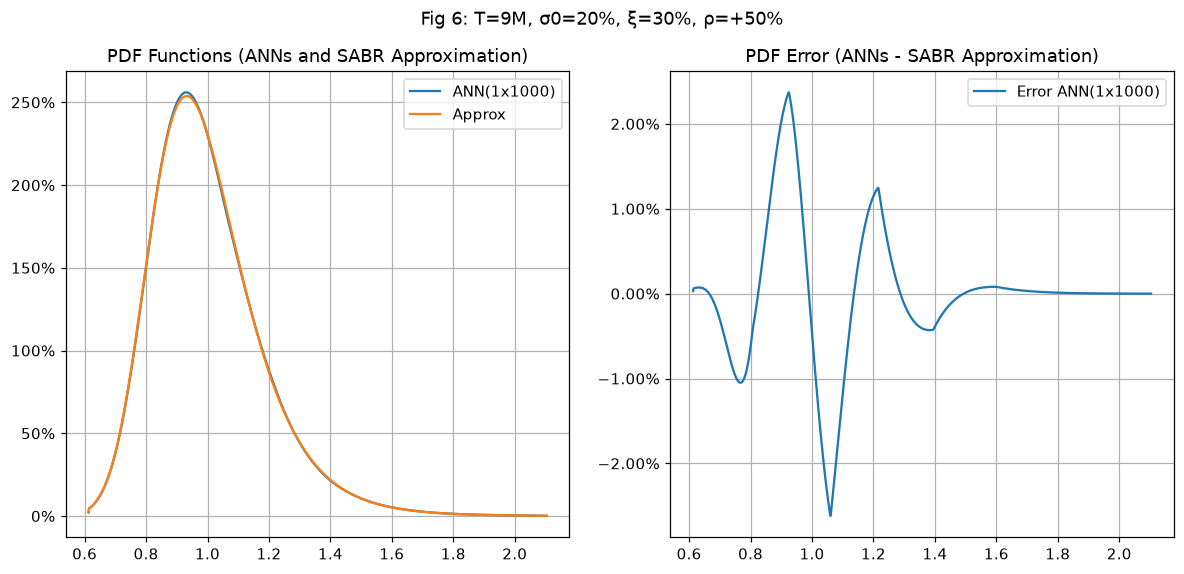

,figure,quantity,ours min (%),ours max (%),paper min (%),paper max (%),within paper range
0,Fig 5,Volatility Smile,-0.0904,0.1146,-0.0300,0.020,False
1,Fig 5,CDF,-0.2667,0.3671,-0.0600,0.040,False
2,Fig 5,PDF,-17.0877,14.6390,-2.0000,2.000,False
3,Fig 6,Volatility Smile,-0.0562,0.0284,-0.0025,0.015,False
4,Fig 6,CDF,-0.0876,0.1344,-0.0200,0.030,False
5,Fig 6,PDF,-2.6180,2.3713,-0.4000,0.400,False


In [9]:
def black_call(K, sig, T):
    s = sig * np.sqrt(T)
    d1 = (-np.log(K) + s**2 / 2) / s
    return norm.cdf(d1) - K * norm.cdf(d1 - s)

def cdf_pdf(K, sig, T):
    dC = np.gradient(black_call(K, sig, T), K)
    return 1 + dC, np.gradient(dC, K)

FIGS2 = {  # paper: smile range, CDF range, max |PDF error|  (all in %)
    "Fig 5: T=1M, σ0=30%, ξ=150%, ρ=−75%": ((1 / 12, 0.30, 1.50, -0.75), (-0.03, 0.02), (-0.06, 0.04), 2.0),
    "Fig 6: T=9M, σ0=20%, ξ=30%, ρ=+50%":  ((0.75, 0.20, 0.30, 0.50), (-0.0025, 0.015), (-0.02, 0.03), 0.4),
}
rows = []
for name, (p, s_rng, c_rng, pdf_max) in FIGS2.items():
    T = p[0]
    Kf, ref, ann = smiles(*p, max(SIZES), n=2000)
    (cr, pr), (ca, pa) = cdf_pdf(Kf, ref, T), cdf_pdf(Kf, ann, T)
    for what, r, a, rng, dec in [("Volatility Smile", ref, ann, s_rng, (2, 4)),
                                 ("CDF", cr, ca, c_rng, (1, 3)),
                                 ("PDF", pr, pa, (-pdf_max, pdf_max), (0, 2))]:
        paper_plot(Kf, r, {f"ANN(1x{max(SIZES)})": a}, what, dec, suptitle=name)
        e = (a - r) * 100
        rows.append({"figure": name[:5], "quantity": what, "ours min (%)": e.min(), "ours max (%)": e.max(),
                     "paper min (%)": rng[0], "paper max (%)": rng[1],
                     "within paper range": rng[0] <= e.min() and e.max() <= rng[1]})
pd.DataFrame(rows).round(4)

## 6. Summary

In [10]:
print(f"Hagan labels vs. Table 6: {check_against_paper():.2f} bp (≈ the paper's rounding)")
print(f"Test-set MAE, N={max(SIZES)}: {np.abs(err[max(SIZES)]).mean():.3f} bp")
print("Figures 2–6: see the 'within paper range' columns above.")

Hagan labels vs. Table 6: 0.53 bp (≈ the paper's rounding)
Test-set MAE, N=1000: 3.550 bp
Figures 2–6: see the 'within paper range' columns above.
